# 2. Churn model: comparison, calibration and threshold analysis

**Goal.** Produce churn probabilities that rank customers well *and* are honest enough to multiply by money. Required baseline: logistic regression plus a tree-based model, with calibration and threshold analysis; stretch: gradient boosting with SHAP.

Numbers in the text were generated for run `20261010T124415068764Z-88be4b93`.

In [1]:
import pandas as pd
from IPython.display import display, Image
from telco_retention.common import ROOT, latest_run, read_json
pd.set_option("display.precision", 4)
run = latest_run()
manifest = read_json(run / "manifest.json")
print("Run:", run.name, "| selected:", manifest["selected_model"], "| threshold:", manifest["threshold"])

Run: 20261010T124415068764Z-88be4b93 | selected: logistic | threshold: 0.35000000000000003


## Validation design

- 5-fold stratified cross-validation on train tunes each family (average precision as the objective).
- Each tuned model is calibrated with a sigmoid fitted on out-of-fold predictions.
- **Selection on validation** with a rule fixed in advance: AP within 0.01 of best calibrated candidate; Brier within 0.002 of best; prefer simpler.
- Test is scored once, with bootstrap intervals.

In [2]:
validation = pd.read_csv(run / "validation_metrics.csv")
display(validation[["model", "variant", "average_precision", "roc_auc", "brier", "ece", "calibration_slope"]])
display(pd.DataFrame(manifest["best_parameters"]).T[["cv_average_precision", "params"]])

,model,variant,average_precision,roc_auc,brier,ece,calibration_slope
0,dummy,raw,0.2654,0.5000,0.1950,0.0186,NaN
1,logistic,raw,0.6686,0.8587,0.1309,0.0261,1.1268
2,logistic,calibrated,0.6686,0.8587,0.1309,0.0261,1.1269
3,random_forest,raw,0.6682,0.8572,0.1317,0.0256,1.1972
4,random_forest,calibrated,0.6682,0.8572,0.1317,0.0301,1.0606
5,xgboost,raw,0.6734,0.8569,0.1309,0.0179,1.0881
6,xgboost,calibrated,0.6734,0.8569,0.1312,0.0258,1.0850


,cv_average_precision,params
logistic,0.6649,"{'model__class_weight': None, 'model__C': 0.1}"
random_forest,0.6701,"{'model__n_estimators': 150, 'model__min_sampl..."
xgboost,0.6765,"{'model__subsample': 1.0, 'model__reg_lambda':..."


**Reading.** On validation the calibrated candidates are within a hundredth of each other in average precision, so the rule picks the simplest: **Logistic Regression**.

## Test results with uncertainty

In [3]:
test = pd.read_csv(run / "test_metrics.csv")
display(test[["model", "average_precision", "roc_auc", "brier", "ece", "calibration_slope", "calibration_intercept", "precision", "recall"]])
display(pd.read_csv(run / "bootstrap_intervals.csv"))

,model,average_precision,roc_auc,brier,ece,calibration_slope,calibration_intercept,precision,recall
0,dummy_raw,0.2654,0.5000,0.1950,0.0217,NaN,0.0006,0.0000,0.0000
1,logistic_raw,0.6195,0.8314,0.1420,0.0203,0.9297,-0.0215,0.5453,0.7086
2,logistic_calibrated,0.6195,0.8314,0.1420,0.0203,0.9297,-0.0220,0.5441,0.7086
3,random_forest_raw,0.6293,0.8313,0.1408,0.0169,0.9897,-0.0247,0.5515,0.6872
4,random_forest_calibrated,0.6293,0.8313,0.1429,0.0354,0.9163,-0.0246,0.5865,0.6524
5,xgboost_raw,0.6331,0.8314,0.1409,0.0192,0.9220,-0.0104,0.5455,0.7059
6,xgboost_calibrated,0.6331,0.8314,0.1433,0.0476,0.9387,-0.0034,0.5764,0.6150


,metric,lower_95,upper_95
0,average_precision,0.5677,0.6693
1,roc_auc,0.8085,0.8525
2,brier,0.1314,0.1529
3,log_loss,0.4025,0.4611
4,precision,0.4989,0.5886
5,recall,0.6630,0.7513
6,f1,0.5736,0.6535
7,ece,0.0173,0.0474
8,calibration_slope,0.8223,1.0499
9,calibration_intercept,-0.1637,0.1269


**Interpretation.** PR-AUC 0.619 against a random baseline of 0.265 (the churn rate) and ROC-AUC 0.831. ECE 0.020 means predicted probabilities are on average about 2.0 percentage points from observed churn; slope 0.93 (target 1) and intercept -0.022 (target 0) show no material over- or under-confidence.

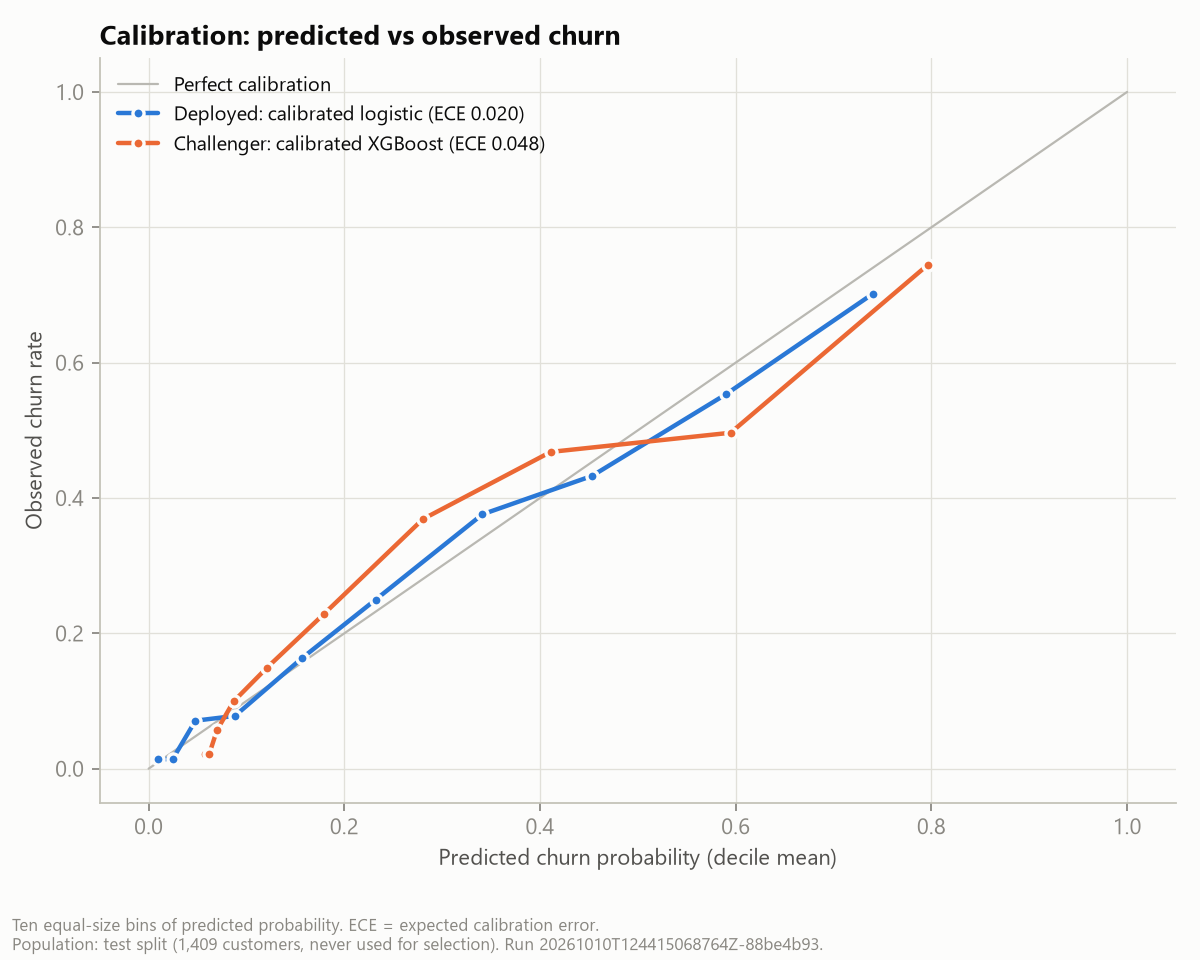

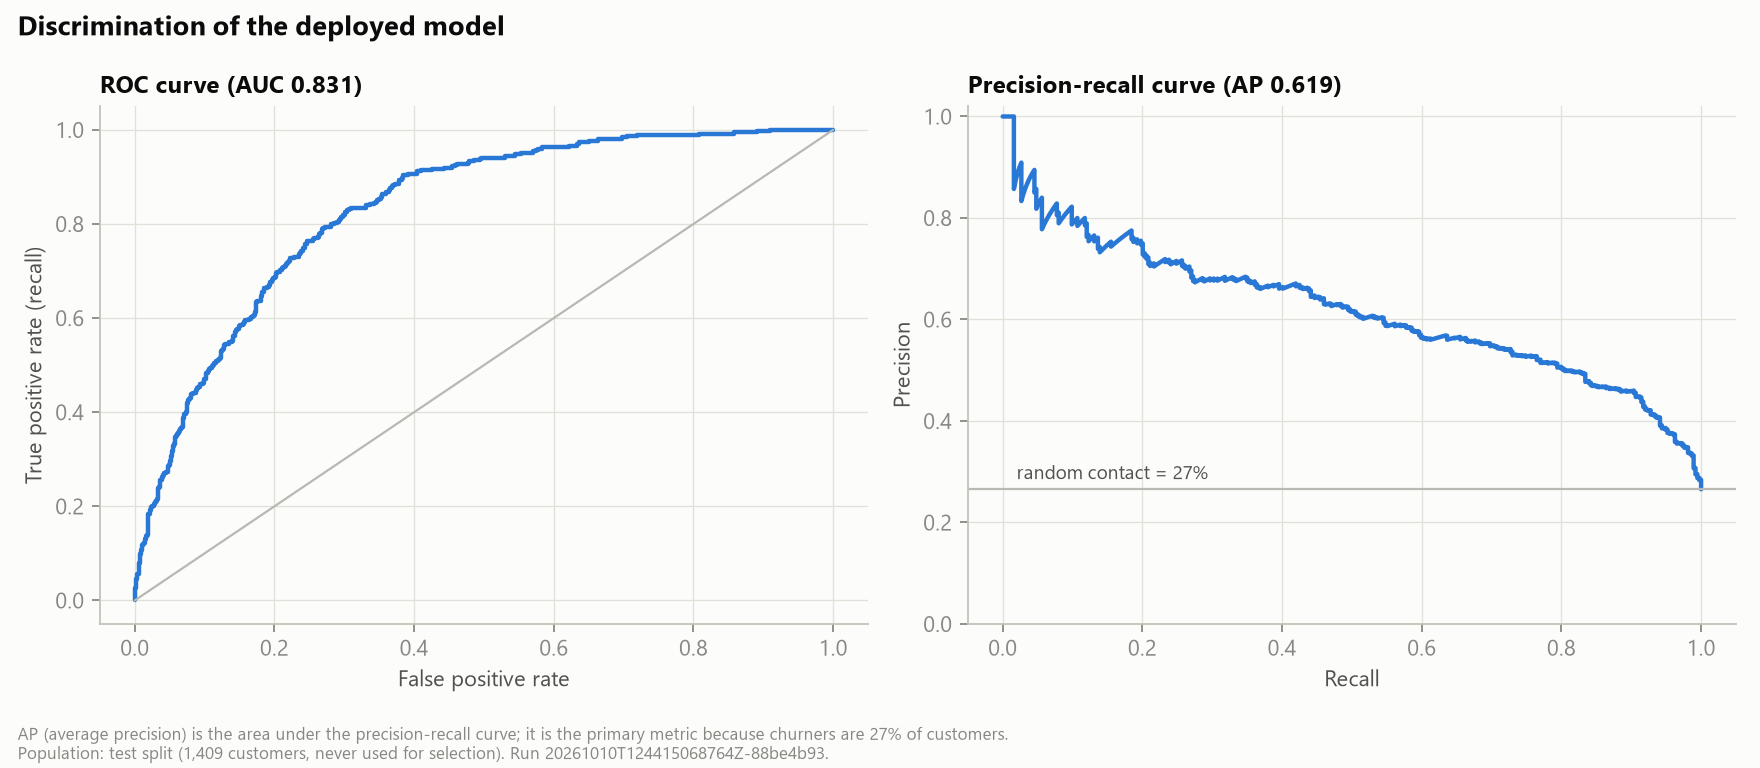

In [4]:
display(Image(filename=str(ROOT / "reports/figures/calibration.png")))
display(Image(filename=str(ROOT / "reports/figures/discrimination.png")))

## Threshold analysis: why one cut-off is not the decision

In [5]:
display(pd.read_csv(run / "threshold_analysis.csv")[["threshold", "precision", "recall", "f1"]].round(3))
display(pd.read_csv(run / "threshold_business.csv"))
display(read_json(run / "break_even.json")["break_even_probability_quantiles"])

,threshold,precision,recall,f1
0,0.05,0.354,0.989,0.521
1,0.10,0.393,0.963,0.559
2,0.15,0.434,0.939,0.593
3,0.20,0.478,0.888,0.622
4,0.25,0.504,0.842,0.631
5,0.30,0.535,0.783,0.636
6,0.35,0.579,0.741,0.650
7,0.40,0.608,0.687,0.645
8,0.45,0.657,0.634,0.645
9,0.50,0.692,0.553,0.615


,rule,customers,cost,expected_net_value,precision,recall
0,Probability >= 0.35 (F1 threshold),487,12175.0,1404.8479,0.5441,0.7086
1,Expected value > 0 (no budget limit),329,8225.0,2915.9133,0.5684,0.5000
2,"Expected value, ranked within the fixed budget",140,3500.0,2130.1545,0.6214,NaN


{'p10': 0.2943546409333618,
 'p25': 0.36409404816988133,
 'p50': 0.5432991995188771,
 'p75': 1.0859460700643673,
 'p90': 1.832907746055055}

**Interpretation.** The F1-best threshold (0.35) treats every customer alike. With value and cost included, the churn probability at which an offer pays off differs by customer, from about 29% for the most valuable to above 100% for the least valuable. Contacting everyone above the F1 threshold spends more and earns less than contacting everyone with positive expected value.

## Gains and drivers

,decile,customers,churn_rate,lift,cumulative_churner_capture
0,1,141,0.7021,2.6452,0.2647
1,2,141,0.5532,2.0841,0.4733
2,3,141,0.4326,1.6299,0.6364
3,4,141,0.3759,1.4161,0.7781
4,5,141,0.2553,0.9619,0.8743
5,6,141,0.1560,0.5878,0.9332
6,7,141,0.0780,0.2939,0.9626
7,8,141,0.0709,0.2672,0.9893
8,9,141,0.0142,0.0534,0.9947
9,10,140,0.0143,0.0538,1.0000


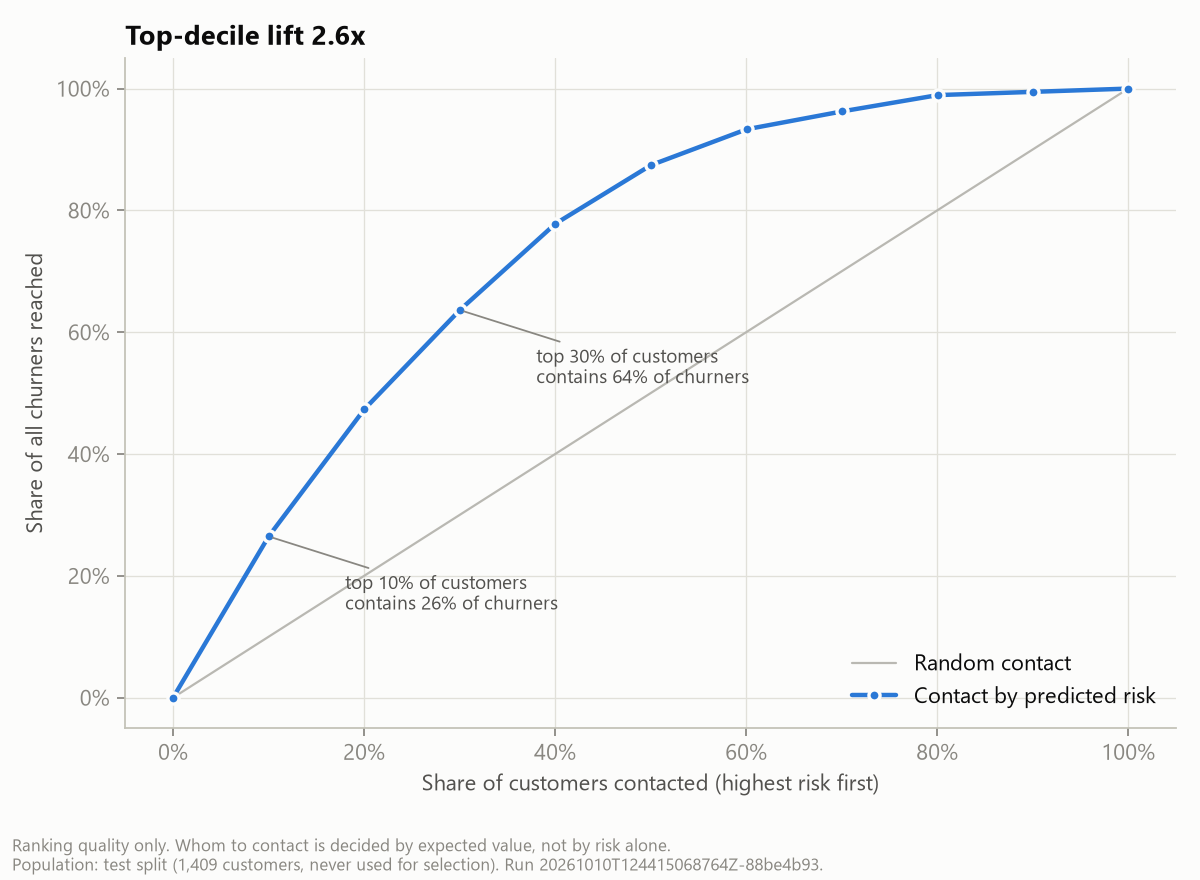

,feature,coefficient
0,tenure,-0.5822
1,Contract_Two year,-0.4208
2,InternetService_DSL,-0.2887
3,tenure_band_loyal,-0.2148
4,MultipleLines_No,-0.2026
5,PaperlessBilling_No,-0.1937
47,tenure_band_new,0.4018
46,monthly_contract,0.3970
45,InternetService_Fiber optic,0.3592
44,OnlineSecurity_No,0.2359


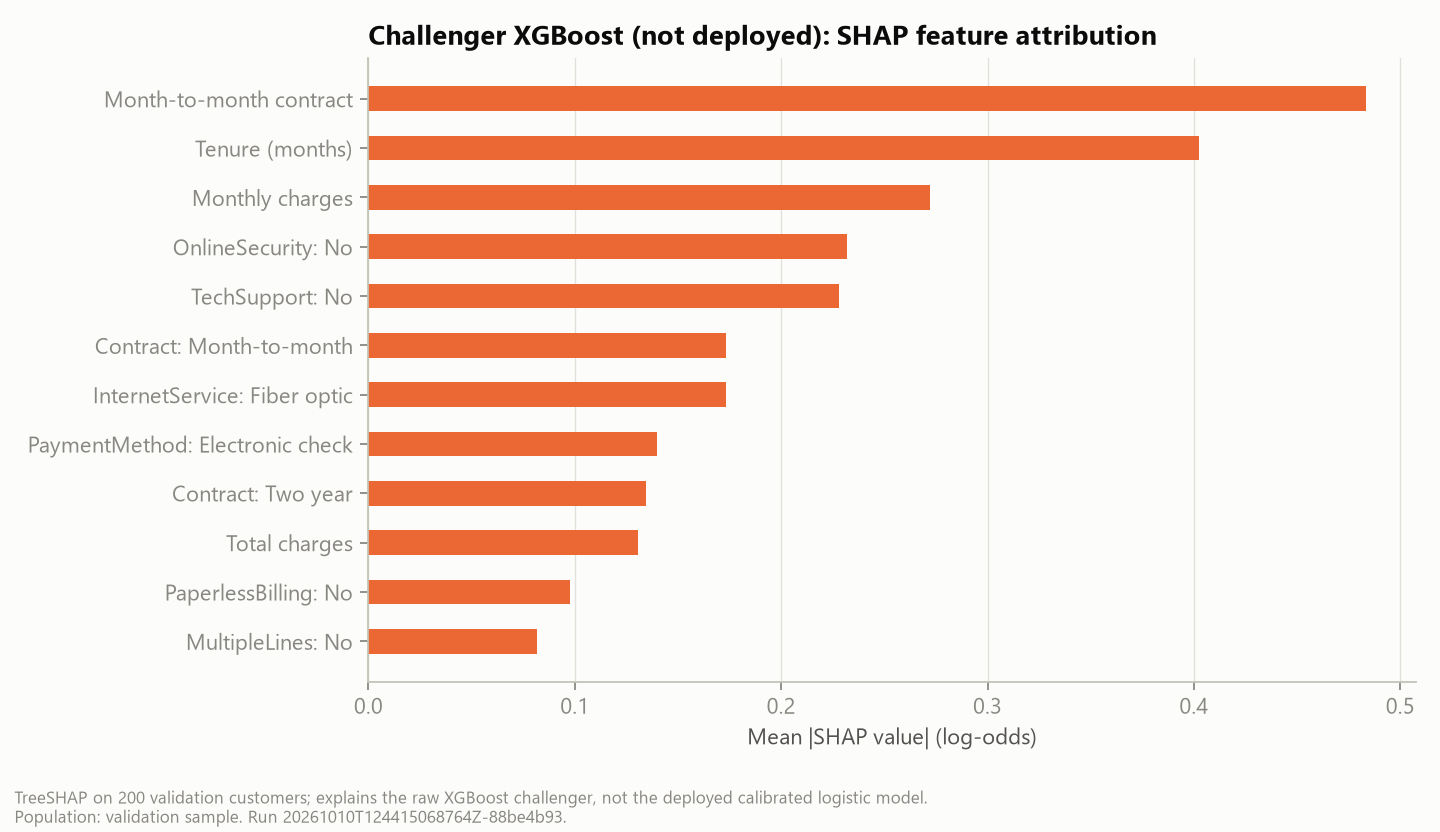

In [6]:
display(pd.read_csv(run / "gains_test.csv")[["decile", "customers", "churn_rate", "lift", "cumulative_churner_capture"]])
display(Image(filename=str(ROOT / "reports/figures/gains.png")))
coefficients = pd.read_csv(run / "logistic_coefficients.csv")
display(pd.concat([coefficients.nsmallest(6, "coefficient"), coefficients.nlargest(6, "coefficient")]))
display(Image(filename=str(ROOT / "reports/figures/shap_challenger.png")))

## Error analysis by segment

In [7]:
errors = pd.read_csv(run / "segment_errors.csv")
display(errors[["attribute", "group", "n", "small_sample", "average_precision", "recall", "brier", "ece"]])

,attribute,group,n,small_sample,average_precision,recall,brier,ece
0,Contract,Month-to-month,786,False,0.6510,0.8086,0.2022,0.0491
1,Contract,One year,284,False,0.3361,0.0833,0.0995,0.0348
2,Contract,Two year,339,False,0.1932,0.0000,0.0379,0.0187
3,InternetService,DSL,482,False,0.5021,0.5116,0.1167,0.0261
4,InternetService,Fiber optic,624,False,0.6692,0.8308,0.2011,0.0348
5,InternetService,No,303,False,0.2245,0.0000,0.0602,0.0396
6,PaymentMethod,Bank transfer (automatic),303,False,0.6631,0.5538,0.1169,0.0603
7,PaymentMethod,Credit card (automatic),307,False,0.5071,0.5600,0.1042,0.0242
8,PaymentMethod,Electronic check,494,False,0.6771,0.8255,0.2033,0.0526
9,PaymentMethod,Mailed check,305,False,0.4590,0.5532,0.1054,0.0510


**So what.** The model is good at ranking and its probabilities are trustworthy enough for expected-value arithmetic. It does not tell us which customers an offer would keep; that remains an assumption tested by the pilot.